# Lab Day 10: Finetune Qwen3-VL-4B (LoRA) để định vị hư hại mặt đường

Mã thật nằm trong `lab/` (`labels.py`, `vlm.py`, `reward.py`, `viz.py`); notebook này gọi các hàm đó theo từng bước của `GUIDE.md`.
Chạy được trên **Colab** (lưu kết quả lên Google Drive) và **Kaggle Notebooks** (lưu vào `/kaggle/working`, dùng "Save Version → Save & Run All" để chạy nền).
Thí nghiệm đã có `report/evidence/eN.json` sẽ được **bỏ qua**; dự đoán trong `report/preds/` được dùng lại.

## 0. Môi trường (Colab T4 hoặc Kaggle GPU)

In [1]:
# Colab: Runtime → Change runtime type → T4 GPU
# Kaggle: Settings → Accelerator = GPU T4 x2 (hoặc P100), Internet = On
import os
ON_KAGGLE = os.path.exists('/kaggle/working')
!nvidia-smi -L
if not ON_KAGGLE:
    from google.colab import drive
    drive.mount('/content/drive')

REPO_URL = 'https://github.com/phuongling2428-wq/K4-Track-4-Day10-VisionLanguageModel.git'
ROOT = '/tmp/lab10' if ON_KAGGLE else '/content/lab10'
if not os.path.exists(ROOT):
    !git clone -q {REPO_URL} {ROOT}
else:
    !git -C {ROOT} pull -q     # lấy bản sửa mới nhất
%cd {ROOT}
!pip -q install -r requirements-colab.txt

GPU 0: Tesla T4 (UUID: GPU-9021ebec-221d-f280-dd7c-60f9eb7d22d1)
GPU 1: Tesla T4 (UUID: GPU-24b9ae03-11fe-a502-045d-b742bd33dd25)
/tmp/lab10
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 41.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 31.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 889.0/889.0 kB 24.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 20.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 47.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 27.6 MB/s eta 0:00:00


In [2]:
import json, shutil, subprocess, functools
from pathlib import Path
import torch

# nơi lưu adapter, dự đoán, bằng chứng (Kaggle: /kaggle/working là thư mục Output tải về được)
DRIVE = Path('/kaggle/working/day10_v2') if ON_KAGGLE else Path('/content/drive/MyDrive/day10_v2')
RUNS, PREDS = DRIVE / 'runs', DRIVE / 'preds'
EVID, FIGS = Path('report/evidence'), Path('report/figures')
for d in (RUNS, PREDS, EVID, FIGS, DRIVE / 'report', Path('report/preds')):
    d.mkdir(parents=True, exist_ok=True)

def sync_report():
    """Chép report/ lên Drive sau mỗi lần chấm (clone trên Colab sẽ mất khi ngắt)."""
    shutil.copytree('report', DRIVE / 'report', dirs_exist_ok=True)

# Khôi phục bằng chứng đã có từ lần chạy trước (nếu session bị ngắt)
if (DRIVE / 'report').exists():
    shutil.copytree(DRIVE / 'report', 'report', dirs_exist_ok=True)
# Dự đoán đã commit trong repo (report/preds/) → dùng lại, không suy luận lại
for f in Path('report/preds').glob('*.jsonl'):
    if not (PREDS / f.name).exists():
        shutil.copy(f, PREDS / f.name)
print('bằng chứng có sẵn:', sorted(x.name for x in EVID.glob('*.json')))
print(torch.__version__, torch.cuda.get_device_name(0))

bằng chứng có sẵn: []
2.11.0+cu128 Tesla T4


## 1. Dữ liệu: tải và chia split

In [3]:
# Tải zip công khai của dataset qua URL trực tiếp (không cần tài khoản/khoá Kaggle).
# Nếu URL lỗi: tải zip về tay, đưa lên Drive rồi dùng --zip /content/drive/MyDrive/<file>.zip
DATA_URL = 'https://www.kaggle.com/api/v1/datasets/download/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes'
if not Path('data/splits/meta.json').exists():
    !python scripts/prepare_data.py --zip "{DATA_URL}"
!python -m pytest -q

dataset_version : d10-21e4070301
  train  1422 ảnh  boxes={'pothole': 1074, 'crack': 1750, 'manhole': 691}
  val     276 ảnh  boxes={'pothole': 66, 'crack': 470, 'manhole': 103}
  test    311 ảnh  boxes={'pothole': 121, 'crack': 299, 'manhole': 163}
...........................s.........................................    [100%]
68 passed, 1 skipped in 0.37s


In [4]:
from scripts.labcommon import read_jsonl
from lab import viz

rows, leak = viz.split_stats()
assert not leak, 'có phiên nằm ở hai split!'
META = json.loads(Path('data/splits/meta.json').read_text())
print('dataset_version =', META['dataset_version'])
train_e, val_e, test_e = (read_jsonl(f'data/splits/{s}.jsonl') for s in ('train', 'val', 'test'))
print(train_e[0])

split    ảnh phiên  rỗng  pothole    crack  manhole
train   1422    13     0     1074     1750      691
val      276     2     0       66      470      103
test     311     3     0      121      299      163
phiên nằm ở >1 split: không có
dataset_version = d10-21e4070301
{'image_id': '20250216_164325', 'image_path': 'images/20250216_164325.jpg', 'width': 640, 'height': 360, 'session': 'phone-20250216', 'objects': [{'label': 'manhole', 'yolo': [0.466407, 0.552778, 0.298437, 0.144444]}, {'label': 'pothole', 'yolo': [0.604688, 0.556944, 0.043751, 0.113889]}, {'label': 'pothole', 'yolo': [0.285156, 0.544444, 0.051562, 0.055555]}, {'label': 'pothole', 'yolo': [0.3875, 0.498611, 0.053124, 0.047222]}, {'label': 'crack', 'yolo': [0.421875, 0.672222, 0.05, 0.088889]}, {'label': 'crack', 'yolo': [0.259375, 0.891666, 0.203126, 0.205555]}, {'label': 'crack', 'yolo': [0.36875, 0.745833, 0.059376, 0.125]}, {'label': 'crack', 'yolo': [0.617188, 0.561111, 0.074999, 0.105556]}, {'label': 'crack', 'yolo

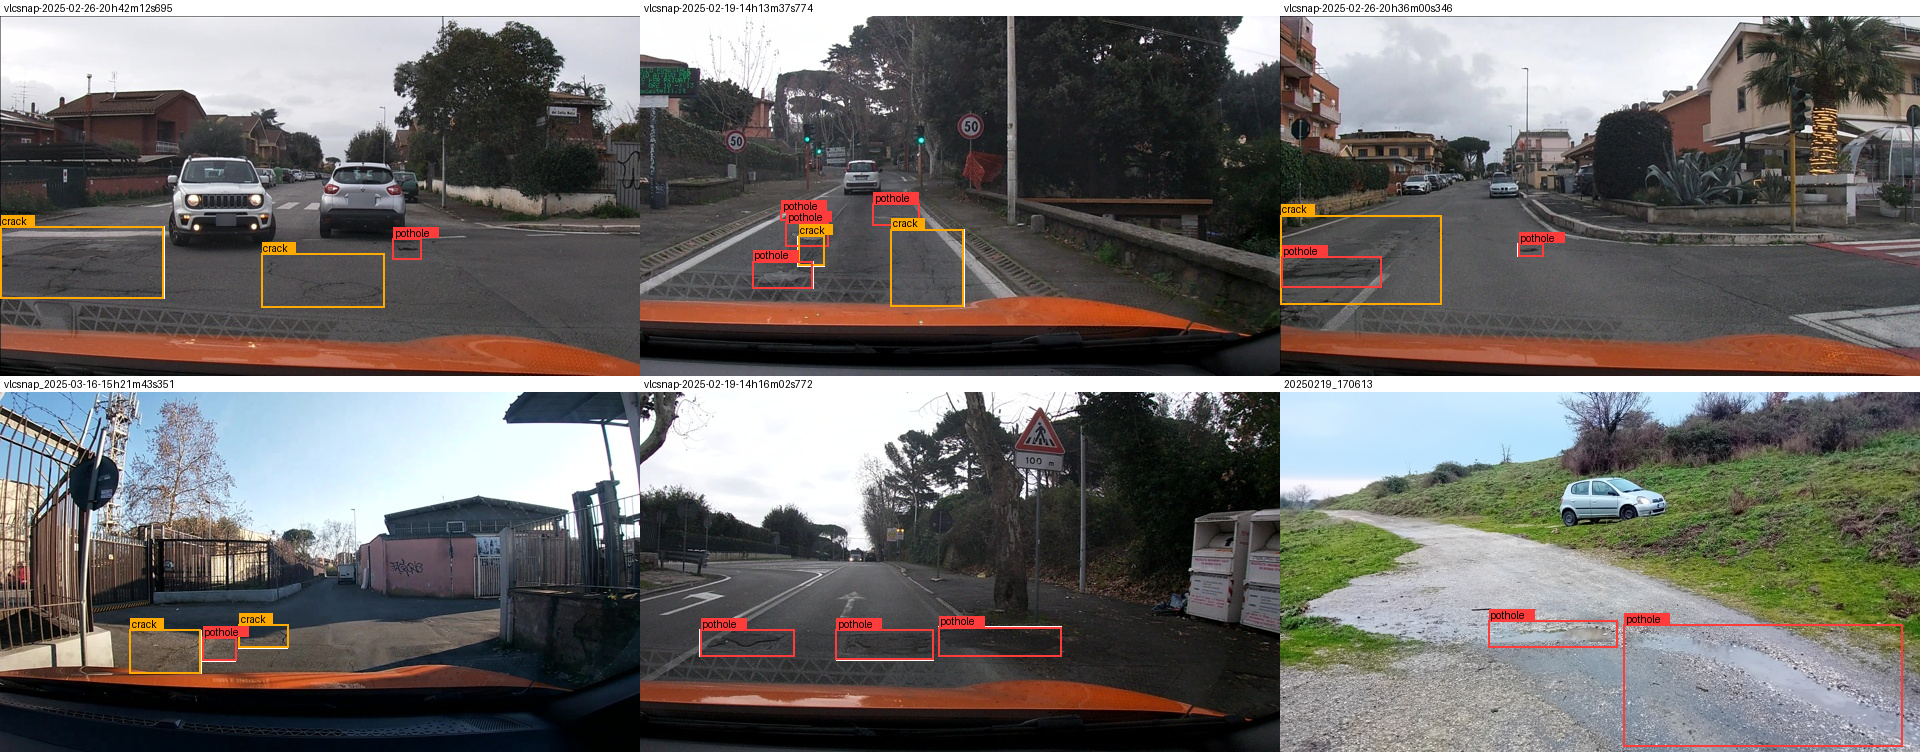

In [5]:
# 6 ảnh có box: trắng = box YOLO gốc, màu = box sau khi đi qua JSON 0–1000 rồi quy ngược về pixel
import random
sample = random.Random(0).sample([e for e in train_e if len(e['objects']) >= 2], 6)
g = viz.grid([viz.draw_gt(e) for e in sample], cols=3, captions=[e['image_id'][:40] for e in sample])
g.save(FIGS / 'gt_samples.jpg', quality=88); g

## 2. Nhãn: YOLO → JSON thang 0–1000

In [6]:
from lab.labels import PROMPT, build_prompt, objects_to_answer, yolo_to_box, box_to_pixel
e = sample[0]
print(PROMPT, '\n')
print('objects:', e['objects'])
print('answer :', objects_to_answer(e['objects']))
# Kiểm tra khứ hồi: 0–1000 → pixel phải trùng box YOLO gốc (sai số làm tròn < 1 px)
for o in e['objects']:
    xc, yc, w, h = o['yolo']
    ref = ((xc - w/2) * 640, (yc - h/2) * 360, (xc + w/2) * 640, (yc + h/2) * 360)
    back = box_to_pixel(yolo_to_box(o['label'], o['yolo'])['bbox_2d'])
    assert max(abs(a - b) for a, b in zip(ref, back)) < 1.0, (ref, back)
print('khứ hồi OK')

Detect every road damage in this dashcam image. Allowed labels: pothole, crack, manhole. Answer with ONLY a JSON list and no other text, in the form [{"label": "pothole", "bbox_2d": [x1, y1, x2, y2]}], where (x1, y1) is the top-left and (x2, y2) the bottom-right corner. Coordinates are integers on a 0-1000 scale relative to the image size (0 = left/top edge, 1000 = right/bottom edge), not pixels. If there is no damage, answer []. 

objects: [{'label': 'crack', 'yolo': [0.128125, 0.686111, 0.25625, 0.2]}, {'label': 'crack', 'yolo': [0.503907, 0.736111, 0.192187, 0.15]}, {'label': 'pothole', 'yolo': [0.635938, 0.647222, 0.043751, 0.055556]}]
answer : [{"label":"crack","bbox_2d":[0,586,256,786]},{"label":"pothole","bbox_2d":[614,619,658,675]},{"label":"crack","bbox_2d":[408,661,600,811]}]
khứ hồi OK


## 3. E0: zero-shot

In [7]:
from lab import vlm
model, processor = vlm.load_model()

# Câu 1: số tham số ViT/projector (fp16, phải ≈ 415M / 27,3M / 81,8M; nếu chỉ bằng một nửa là ViT đã bị lượng tử)
def n_params(f):
    return sum(p.numel() for n, p in model.named_parameters() if f(n))
print('ViT (gồm projector):', f"{n_params(lambda n: 'visual' in n):,}")
print('  visual.merger     :', f"{n_params(lambda n: 'visual.merger' in n):,}")
print('  deepstack_mergers :', f"{n_params(lambda n: 'deepstack_merger_list' in n):,}")
print('dtype ViT:', next(model.model.visual.parameters()).dtype,
      '· kiểu lớp q_proj LLM:', type(model.model.language_model.layers[0].self_attn.q_proj).__name__)
print(f'VRAM sau khi nạp: {torch.cuda.memory_allocated()/2**30:.2f} GB')

config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/64.7k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

...

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

ViT (gồm projector): 415,347,712
  visual.merger     : 27,271,680
  deepstack_mergers : 81,833,472
dtype ViT: torch.float16 · kiểu lớp q_proj LLM: Linear4bit
VRAM sau khi nạp: 3.27 GB


In [8]:
def score(pred, name, out, coord='norm1000', split='test', meta=None, splits_dir='data/splits'):
    cmd = ['python', 'scripts/score.py', '--pred', str(pred), '--name', name, '--out', str(out),
           '--coord', coord, '--split', split, '--splits-dir', str(splits_dir)]
    for k, v in (meta or {}).items():
        cmd += ['--meta', f'{k}={v}']
    print(subprocess.run(cmd, capture_output=True, text=True, check=True).stdout)
    if Path(pred).parent != Path('report/preds'):       # giữ dự đoán thô trong repo làm bằng chứng
        shutil.copy(pred, Path('report/preds') / Path(pred).name)
    sync_report()
    return json.loads(Path(out).read_text())

# Gỡ lỗi nhanh trên 40 ảnh val trước khi chạy cả test
# score.py chấm cả split, nên dựng một thư mục split chỉ chứa đúng 40 ảnh này
from scripts.labcommon import write_jsonl
VAL40 = Path('/tmp/val40'); write_jsonl(VAL40 / 'val.jsonl', val_e[:40])
shutil.copy('data/splits/meta.json', VAL40 / 'meta.json')
vlm.predict(model, processor, val_e[:40], 'data', PROMPT, PREDS / 'e0_val40.jsonl')
score(PREDS / 'e0_val40.jsonl', 'E0-val40', DRIVE / 'debug_e0_val40.json', split='val', splits_dir=VAL40);

  40/40 ảnh · 1.0 phút
E0-val40 [val] n=40 valid=1.000 P=0.200 R=0.082 F1=0.116 CI95=0.056-0.187 meanIoU=0.630 FP/img=0.80
   pothole  P=0.000 R=0.000 F1=0.000
   crack    P=0.000 R=0.000 F1=0.000
   manhole  P=0.444 R=0.267 F1=0.333



In [9]:
vlm.predict(model, processor, test_e, 'data', PROMPT, PREDS / 'e0.jsonl')
r0 = score(PREDS / 'e0.jsonl', 'E0', EVID / 'e0.json')
for r in read_jsonl(PREDS / 'e0.jsonl')[:5]:
    print(repr(r['raw'][:300]), '\n')

  40/311 ảnh · 0.8 phút
  80/311 ảnh · 1.7 phút
  120/311 ảnh · 3.6 phút
  160/311 ảnh · 4.8 phút
  200/311 ảnh · 5.9 phút
  240/311 ảnh · 7.2 phút
  280/311 ảnh · 9.3 phút
  311/311 ảnh · 9.9 phút
E0 [test] n=311 valid=0.958 P=0.158 R=0.086 F1=0.111 CI95=0.084-0.143 meanIoU=0.619 FP/img=0.86
   pothole  P=0.269 R=0.116 F1=0.162
   crack    P=0.037 R=0.023 F1=0.029
   manhole  P=0.382 R=0.178 F1=0.243

'[{"label": "manhole", "bbox_2d": [770, 640, 843, 684]}]' 

'[]' 

'[{"label": "manhole", "bbox_2d": [297, 684, 399, 714]}]' 

'[]' 

'[{"label": "manhole", "bbox_2d": [253, 624, 330, 658]}]' 



In [10]:
# Câu 2: phân loại lỗi của E0
from scripts.score import parse_output
from collections import Counter
cnt = Counter()
for r in read_jsonl(PREDS / 'e0.jsonl'):
    raw, p = r['raw'], parse_output(r['raw'])
    if p is None: cnt['JSON hỏng'] += 1; continue
    if '```' in raw: cnt['bọc ```json'] += 1
    if any(b['label'] not in ('pothole', 'crack', 'manhole') for b in p): cnt['nhãn ngoài 3 lớp'] += 1
    if any(max(b['bbox']) > 1000 for b in p): cnt['toạ độ > 1000 (thang pixel?)'] += 1
    if not p: cnt['trả []'] += 1
print(cnt)
del model; vlm.cleanup()

Counter({'trả []': 31, 'JSON hỏng': 13})


## 4. Dựng dữ liệu huấn luyện: chat template và mask loss

In [11]:
from transformers import AutoProcessor
processor = AutoProcessor.from_pretrained(vlm.MODEL_ID); processor.tokenizer.padding_side = 'left'
ds = vlm.GroundingDataset(train_e, 'data', processor, PROMPT)
ex = ds[0]
pad = processor.tokenizer.convert_tokens_to_ids('<|image_pad|>')
print('số token ảnh:', int((ex['input_ids'] == pad).sum()), '· grid', ex['image_grid_thw'].tolist())
print('tổng token:', ex['input_ids'].shape[1], '· token có loss:', int((ex['labels'] != -100).sum()))
print('phần được học:', repr(processor.tokenizer.decode(ex['input_ids'][ex['labels'] != -100])))
print('đáp án       :', repr(ds.answer(train_e[0])))
batch = vlm.collate([ds[0], ds[1]], processor.tokenizer.pad_token_id)
print({k: tuple(v.shape) for k, v in batch.items()})

số token ảnh: 220 · grid [[1, 22, 40]]
tổng token: 616 · token có loss: 250
phần được học: '[{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]<|im_end|>\n'
đáp án       : '[{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]'
{'input_ids': (2, 616), 'atten

## 5. Setup LoRA / đóng băng cho E1, E2, E3

`vlm.apply_setup(model, targets, train_projector)`: đóng băng mọi tham số, bật gradient checkpointing, gắn LoRA r=16 theo regex (`LLM_TARGETS` 252 module; thêm `VIT_TARGETS` 96 module ở E3), rồi với E2/E3 mở `visual.merger` + `visual.deepstack_merger_list` ở float32. Số module khớp và số tham số được ghi vào `runs/eN/setup.json`.

## 6. Vòng huấn luyện

`vlm.train`: AdamW lr 2e-4, warmup 5% + cosine, fp16 autocast + GradScaler, batch 2 × tích luỹ 4, 300 bước, clip grad 1.0, dừng nếu loss không hữu hạn; lưu adapter **và** `extra_trainable.pt` (projector) mỗi 100 bước; ghi `run.json`.

In [12]:
def run_experiment(key, targets='llm', train_projector=False, r=16, alpha=32, train_fraction=1.0,
                   coord='norm1000', max_steps=300, evidence_name=None):
    """Huấn luyện (nếu chưa có run.json trên Drive) → nạp lại → suy luận test → chấm."""
    if (EVID / f'{key}.json').exists():          # đã xong ở phiên trước: bỏ qua
        print(key, 'đã có bằng chứng, bỏ qua'); return json.loads((EVID / f'{key}.json').read_text())
    out = RUNS / key
    prompt = build_prompt(coord)
    if not (out / 'run.json').exists():
        model, processor = vlm.load_model()
        model, info = vlm.apply_setup(model, targets, train_projector, r=r, alpha=alpha)
        (out).mkdir(parents=True, exist_ok=True)
        (out / 'setup.json').write_text(json.dumps(info, indent=2))
        entries = vlm.subsample(train_e, train_fraction)
        ds = vlm.GroundingDataset(entries, 'data', processor, prompt, coord)
        run = vlm.train(model, ds, functools.partial(vlm.collate, pad_id=processor.tokenizer.pad_token_id),
                        out, max_steps=max_steps)
        print(run)
        del model; vlm.cleanup()
    run = json.loads((out / 'run.json').read_text())
    pred = PREDS / f'{key}.jsonl'
    model, processor = vlm.load_trained(out)
    vlm.predict(model, processor, test_e, 'data', prompt, pred, batch_size=8)   # batch 8: nhanh gấp ~2
    del model; vlm.cleanup()
    meta = {k: run[k] for k in ('trainable_params', 'peak_vram_gb', 'train_minutes')}
    return score(pred, evidence_name or key.upper(), EVID / f'{key}.json', coord=coord, meta=meta)

def plot_loss(*keys):
    import matplotlib.pyplot as plt
    for k in keys:
        log = json.loads((RUNS / k / 'train_log.json').read_text())
        plt.plot([x['step'] for x in log], [x['loss'] for x in log], label=k.upper())
    plt.xlabel('bước'); plt.ylabel('loss'); plt.legend(); plt.grid(alpha=.3)
    plt.savefig(FIGS / 'loss.png', dpi=120, bbox_inches='tight'); plt.show()

## 7. Suy luận và chấm E1–E3

In [13]:
r1 = run_experiment('e1', targets='llm', train_projector=False)

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

LoRA trên 252 module · tham số huấn luyện 33,030,144 (projector 0) / 2,654,188,032


[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


step    1/300 loss 2.0504 gnorm 7.56 lr 2.67e-05 · 0.2 phút · VRAM đỉnh 5.44 GB
step   10/300 loss 0.7714 gnorm 0.57 lr 1.47e-04 · 1.6 phút · VRAM đỉnh 5.81 GB
step   20/300 loss 0.7398 gnorm 0.57 lr 2.00e-04 · 3.2 phút · VRAM đỉnh 6.55 GB
step   30/300 loss 0.6608 gnorm 0.51 lr 1.99e-04 · 4.8 phút · VRAM đỉnh 6.55 GB
step   40/300 loss 0.6005 gnorm 1.22 lr 1.96e-04 · 6.3 phút · VRAM đỉnh 6.55 GB
step   50/300 loss 0.6168 gnorm 0.46 lr 1.93e-04 · 7.9 phút · VRAM đỉnh 6.55 GB
step   60/300 loss 0.6198 gnorm 0.51 lr 1.88e-04 · 9.5 phút · VRAM đỉnh 6.55 GB
step   70/300 loss 0.6410 gnorm 0.40 lr 1.82e-04 · 11.0 phút · VRAM đỉnh 6.55 GB
step   80/300 loss 0.6019 gnorm 0.61 lr 1.75e-04 · 12.6 phút · VRAM đỉnh 6.55 GB
step   90/300 loss 0.6332 gnorm 0.47 lr 1.68e-04 · 14.2 phút · VRAM đỉnh 6.55 GB
step  100/300 loss 0.5822 gnorm 0.38 lr 1.59e-04 · 15.8 phút · VRAM đỉnh 6.55 GB
step  110/300 loss 0.6234 gnorm 0.35 lr 1.50e-04 · 17.4 phút · VRAM đỉnh 6.55 GB
step  120/300 loss 0.6342 gnorm 0.3

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

  80/311 ảnh · 2.2 phút
  160/311 ảnh · 4.8 phút
  240/311 ảnh · 7.4 phút
  311/311 ảnh · 10.2 phút
E1 [test] n=311 valid=0.997 P=0.284 R=0.245 F1=0.263 CI95=0.227-0.301 meanIoU=0.679 FP/img=1.16
   pothole  P=0.231 R=0.149 F1=0.181
   crack    P=0.189 R=0.214 F1=0.201
   manhole  P=0.701 R=0.374 F1=0.488



In [14]:
r2 = run_experiment('e2', targets='llm', train_projector=True)

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

LoRA trên 252 module · tham số huấn luyện 142,135,296 (projector 109,105,152) / 2,654,188,032
step    1/300 loss 2.0504 gnorm 8.10 lr 2.67e-05 · 0.2 phút · VRAM đỉnh 6.32 GB
step   10/300 loss 0.7404 gnorm 0.91 lr 1.47e-04 · 1.6 phút · VRAM đỉnh 7.50 GB
step   20/300 loss 0.7099 gnorm 0.86 lr 2.00e-04 · 3.2 phút · VRAM đỉnh 8.25 GB
step   30/300 loss 0.6686 gnorm 0.67 lr 1.99e-04 · 4.8 phút · VRAM đỉnh 8.25 GB
step   40/300 loss 0.6087 gnorm 0.53 lr 1.96e-04 · 6.4 phút · VRAM đỉnh 8.25 GB
step   50/300 loss 0.6217 gnorm 0.63 lr 1.93e-04 · 8.0 phút · VRAM đỉnh 8.25 GB
step   60/300 loss 0.6202 gnorm 0.56 lr 1.88e-04 · 9.6 phút · VRAM đỉnh 8.25 GB
step   70/300 loss 0.6375 gnorm 0.63 lr 1.82e-04 · 11.2 phút · VRAM đỉnh 8.25 GB
step   80/300 loss 0.5679 gnorm 0.99 lr 1.75e-04 · 12.8 phút · VRAM đỉnh 8.25 GB
step   90/300 loss 0.6204 gnorm 0.62 lr 1.68e-04 · 14.4 phút · VRAM đỉnh 8.25 GB
step  100/300 loss 0.5681 gnorm 0.80 lr 1.59e-04 · 16.0 phút · VRAM đỉnh 8.25 GB
step  110/300 loss 0.5

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

đã nạp 24 tensor projector từ extra_trainable.pt
  80/311 ảnh · 2.2 phút
  160/311 ảnh · 4.8 phút
  240/311 ảnh · 7.7 phút
  311/311 ảnh · 10.6 phút
E2 [test] n=311 valid=0.994 P=0.355 R=0.322 F1=0.338 CI95=0.300-0.377 meanIoU=0.674 FP/img=1.10
   pothole  P=0.211 R=0.165 F1=0.185
   crack    P=0.262 R=0.284 F1=0.273
   manhole  P=0.748 R=0.509 F1=0.606



In [15]:
!git -C /tmp/lab10 pull -q
import sys, gc, importlib, torch, lab.vlm
sys.last_traceback = sys.last_value = None   # nhả model của lần lỗi khỏi VRAM
gc.collect(); torch.cuda.empty_cache()
vlm = importlib.reload(lab.vlm)
print('torchao fix:', hasattr(vlm, 'ignore_old_torchao'),
      f'· VRAM đang dùng {torch.cuda.memory_allocated()/2**30:.2f} GB')


torchao fix: True · VRAM đang dùng 0.02 GB


In [16]:
import sys, gc, torch
for k in ('last_exc', 'last_traceback', 'last_value', 'last_type'):
    if hasattr(sys, k): setattr(sys, k, None)
ip = get_ipython()
ip.InteractiveTB.tb = None if hasattr(ip.InteractiveTB, 'tb') else None
for name in ('model', 'processor', 'trainer'):
    globals().pop(name, None)
gc.collect(); torch.cuda.empty_cache()
print(f'VRAM đang dùng {torch.cuda.memory_allocated()/2**30:.2f} GB')


VRAM đang dùng 0.02 GB


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

LoRA trên 348 module · tham số huấn luyện 148,426,752 (projector 109,105,152) / 2,660,479,488
step    1/300 loss 2.0504 gnorm 8.45 lr 2.67e-05 · 0.2 phút · VRAM đỉnh 8.39 GB
step   10/300 loss 0.7850 gnorm 1.27 lr 1.47e-04 · 1.8 phút · VRAM đỉnh 9.61 GB
step   20/300 loss 0.7337 gnorm 0.72 lr 2.00e-04 · 3.5 phút · VRAM đỉnh 10.36 GB
step   30/300 loss 0.6321 gnorm 1.22 lr 1.99e-04 · 5.3 phút · VRAM đỉnh 10.36 GB
step   40/300 loss 0.6080 gnorm 1.30 lr 1.96e-04 · 7.1 phút · VRAM đỉnh 10.36 GB
step   50/300 loss 0.5654 gnorm 1.28 lr 1.93e-04 · 8.8 phút · VRAM đỉnh 10.36 GB
step   60/300 loss 0.5799 gnorm 1.01 lr 1.88e-04 · 10.6 phút · VRAM đỉnh 10.36 GB
step   70/300 loss 0.6281 gnorm 1.21 lr 1.82e-04 · 12.4 phút · VRAM đỉnh 10.36 GB
step   80/300 loss 0.5942 gnorm 5.13 lr 1.75e-04 · 14.1 phút · VRAM đỉnh 10.36 GB
step   90/300 loss 0.5435 gnorm 0.92 lr 1.68e-04 · 15.9 phút · VRAM đỉnh 10.36 GB
step  100/300 loss 0.5409 gnorm 2.02 lr 1.59e-04 · 17.7 phút · VRAM đỉnh 10.36 GB
step  110/30

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

đã nạp 24 tensor projector từ extra_trainable.pt
  80/311 ảnh · 2.5 phút
  160/311 ảnh · 4.8 phút
  240/311 ảnh · 7.7 phút
  311/311 ảnh · 10.2 phút
E3 [test] n=311 valid=1.000 P=0.468 R=0.413 F1=0.439 CI95=0.399-0.480 meanIoU=0.696 FP/img=0.88
   pothole  P=0.303 R=0.223 F1=0.257
   crack    P=0.383 R=0.388 F1=0.385
   manhole  P=0.797 R=0.601 F1=0.685



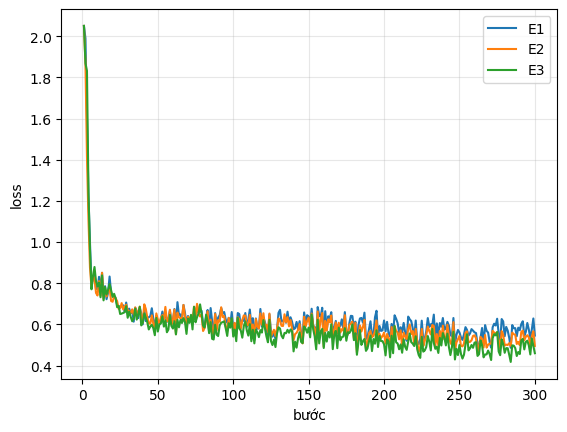

e1 {'matched_modules': 252, 'trainable_params': 33030144, 'projector_params': 0, 'total_params': 2654188032}
e2 {'matched_modules': 252, 'trainable_params': 142135296, 'projector_params': 109105152, 'total_params': 2654188032}
e3 {'matched_modules': 348, 'trainable_params': 148426752, 'projector_params': 109105152, 'total_params': 2660479488}


In [17]:
r3 = run_experiment('e3', targets='llm+vit', train_projector=True)
plot_loss('e1', 'e2', 'e3')
for k in ('e1', 'e2', 'e3'):
    print(k, json.loads((RUNS / k / 'setup.json').read_text()))

In [18]:
# Câu 3: chấm lại dự đoán E1 (thang 0–1000) như thể là pixel → F1 sụp. Không đặt vào evidence/.
Path('report/extra').mkdir(exist_ok=True)
score(PREDS / 'e1.jsonl', 'E1-as-pixel', 'report/extra/e1_scored_as_pixel.json', coord='pixel')

E1-as-pixel [test] n=311 valid=0.997 P=0.000 R=0.000 F1=0.000 CI95=0.000-0.000 meanIoU=0.000 FP/img=1.62
   pothole  P=0.000 R=0.000 F1=0.000
   crack    P=0.000 R=0.000 F1=0.000
   manhole  P=0.000 R=0.000 F1=0.000



{'n_images': 311,
 'parse_valid_rate': 0.9967845659163987,
 'missing_predictions': 0,
 'micro': {'precision': 0.0,
  'recall': 0.0,
  'f1': 0.0,
  'tp': 0,
  'fp': 504,
  'fn': 583},
 'per_class': {'pothole': {'precision': 0.0,
   'recall': 0.0,
   'f1': 0.0,
   'tp': 0,
   'fp': 78,
   'fn': 121},
  'crack': {'precision': 0.0,
   'recall': 0.0,
   'f1': 0.0,
   'tp': 0,
   'fp': 339,
   'fn': 299},
  'manhole': {'precision': 0.0,
   'recall': 0.0,
   'f1': 0.0,
   'tp': 0,
   'fp': 87,
   'fn': 163},
  'other': {'precision': 0.0,
   'recall': 0.0,
   'f1': 0.0,
   'tp': 0,
   'fp': 0,
   'fn': 0}},
 'mean_iou': 0.0,
 'fp_per_image': 1.6205787781350482,
 'f1_ci95': [0.0, 0.0],
 'score_version': 1,
 'name': 'E1-as-pixel',
 'dataset_version': 'd10-21e4070301',
 'split': 'test',
 'coord': 'pixel',
 'meta': {}}

## 8. E4: ablation (đổi đúng một biến so với setup tốt nhất)

Mặc định chọn `coord_scale` (nối thẳng với câu 3). Đổi `E4_VAR` thành `'rank'` hoặc `'data_size'` nếu muốn.
Giá trị gốc của setup tốt nhất được chấm lại từ chính dự đoán của nó (không cần chạy lại).

In [19]:
SETUPS = {'e1': dict(targets='llm', train_projector=False),
          'e2': dict(targets='llm', train_projector=True),
          'e3': dict(targets='llm+vit', train_projector=True)}
ev = {k: json.loads((EVID / f'{k}.json').read_text()) for k in SETUPS}
BEST = max(ev, key=lambda k: ev[k]['micro']['f1'])
print('setup tốt nhất:', BEST, {k: round(v['micro']['f1'], 3) for k, v in ev.items()})

E4_VAR = 'coord_scale'            # 'rank' | 'data_size' | 'coord_scale'
base = SETUPS[BEST]
if E4_VAR == 'coord_scale':
    base_val, new_val, new_kw = 'norm1000', 'pixel', dict(coord='pixel')
elif E4_VAR == 'rank':
    base_val, new_val, new_kw = 16, 64, dict(r=64, alpha=128)   # (hoặc 4 → r=4, alpha=8)
else:
    base_val, new_val, new_kw = 1.0, 0.1, dict(train_fraction=0.1)

base_meta = {k: ev[BEST]['meta'][k] for k in ('trainable_params', 'peak_vram_gb', 'train_minutes')}
score(PREDS / f'{BEST}.jsonl', f'E4 {E4_VAR}={base_val}', EVID / f'e4_{E4_VAR}_{base_val}.json', meta=base_meta)
r4 = run_experiment(f'e4_{E4_VAR}_{new_val}', **base, **new_kw, evidence_name=f'E4 {E4_VAR}={new_val}')

setup tốt nhất: e3 {'e1': 0.263, 'e2': 0.338, 'e3': 0.439}
E4 coord_scale=norm1000 [test] n=311 valid=1.000 P=0.468 R=0.413 F1=0.439 CI95=0.399-0.480 meanIoU=0.696 FP/img=0.88
   pothole  P=0.303 R=0.223 F1=0.257
   crack    P=0.383 R=0.388 F1=0.385
   manhole  P=0.797 R=0.601 F1=0.685



Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

LoRA trên 348 module · tham số huấn luyện 148,426,752 (projector 109,105,152) / 2,660,479,488
step    1/300 loss 2.0221 gnorm 8.11 lr 2.67e-05 · 0.2 phút · VRAM đỉnh 8.37 GB
step   10/300 loss 0.7781 gnorm 0.91 lr 1.47e-04 · 1.8 phút · VRAM đỉnh 9.61 GB
step   20/300 loss 0.6562 gnorm 0.47 lr 2.00e-04 · 3.5 phút · VRAM đỉnh 10.34 GB
step   30/300 loss 0.6551 gnorm 0.83 lr 1.99e-04 · 5.3 phút · VRAM đỉnh 10.34 GB
step   40/300 loss 0.6343 gnorm 2.49 lr 1.96e-04 · 7.1 phút · VRAM đỉnh 10.34 GB
step   50/300 loss 0.6140 gnorm 0.62 lr 1.93e-04 · 8.8 phút · VRAM đỉnh 10.34 GB
step   60/300 loss 0.6125 gnorm 0.76 lr 1.88e-04 · 10.6 phút · VRAM đỉnh 10.34 GB
step   70/300 loss 0.6203 gnorm 1.43 lr 1.82e-04 · 12.3 phút · VRAM đỉnh 10.34 GB
step   80/300 loss 0.5768 gnorm 1.00 lr 1.75e-04 · 14.1 phút · VRAM đỉnh 10.34 GB
step   90/300 loss 0.6471 gnorm 2.65 lr 1.68e-04 · 15.9 phút · VRAM đỉnh 10.34 GB
step  100/300 loss 0.5605 gnorm 1.20 lr 1.59e-04 · 17.6 phút · VRAM đỉnh 10.34 GB
step  110/30

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

đã nạp 24 tensor projector từ extra_trainable.pt
  80/311 ảnh · 2.1 phút
  160/311 ảnh · 4.4 phút
  240/311 ảnh · 7.5 phút
  311/311 ảnh · 9.9 phút
E4 coord_scale=pixel [test] n=311 valid=1.000 P=0.426 R=0.389 F1=0.407 CI95=0.370-0.446 meanIoU=0.683 FP/img=0.98
   pothole  P=0.276 R=0.223 F1=0.247
   crack    P=0.339 R=0.348 F1=0.343
   manhole  P=0.750 R=0.589 F1=0.660



## 10. Ảnh minh hoạ và bảng tổng hợp

e0_dung_1.jpg dung TP=2 FP=0 FN=0 ['manhole', 'manhole'] → ['manhole', 'manhole']
e0_dung_2.jpg dung TP=1 FP=0 FN=0 ['manhole'] → ['manhole']
e0_dung_3.jpg dung TP=1 FP=0 FN=0 ['crack'] → ['crack']
e0_sai_1.jpg sai TP=0 FP=3 FN=7 ['pothole', 'pothole', 'pothole', 'pothole', 'crack', 'crack', 'crack'] → ['crack', 'pothole', 'pothole']
e0_sai_2.jpg sai TP=0 FP=3 FN=5 ['crack', 'pothole', 'pothole', 'pothole', 'pothole'] → ['crack', 'crack', 'crack']
e0_sai_3.jpg sai TP=0 FP=3 FN=4 ['crack', 'crack', 'crack', 'crack'] → ['pothole', 'crack', 'manhole']
e3_dung_1.jpg dung TP=3 FP=0 FN=0 ['crack', 'manhole', 'pothole'] → ['crack', 'manhole', 'pothole']
e3_dung_2.jpg dung TP=2 FP=0 FN=0 ['manhole', 'manhole'] → ['manhole', 'manhole']
e3_dung_3.jpg dung TP=2 FP=0 FN=0 ['manhole', 'manhole'] → ['manhole', 'manhole']
e3_sai_1.jpg sai TP=0 FP=6 FN=4 ['pothole', 'pothole', 'pothole', 'crack'] → ['crack', 'crack', 'crack', 'crack', 'crack', 'crack']
e3_sai_2.jpg sai TP=1 FP=3 FN=6 ['pothole', 'poth

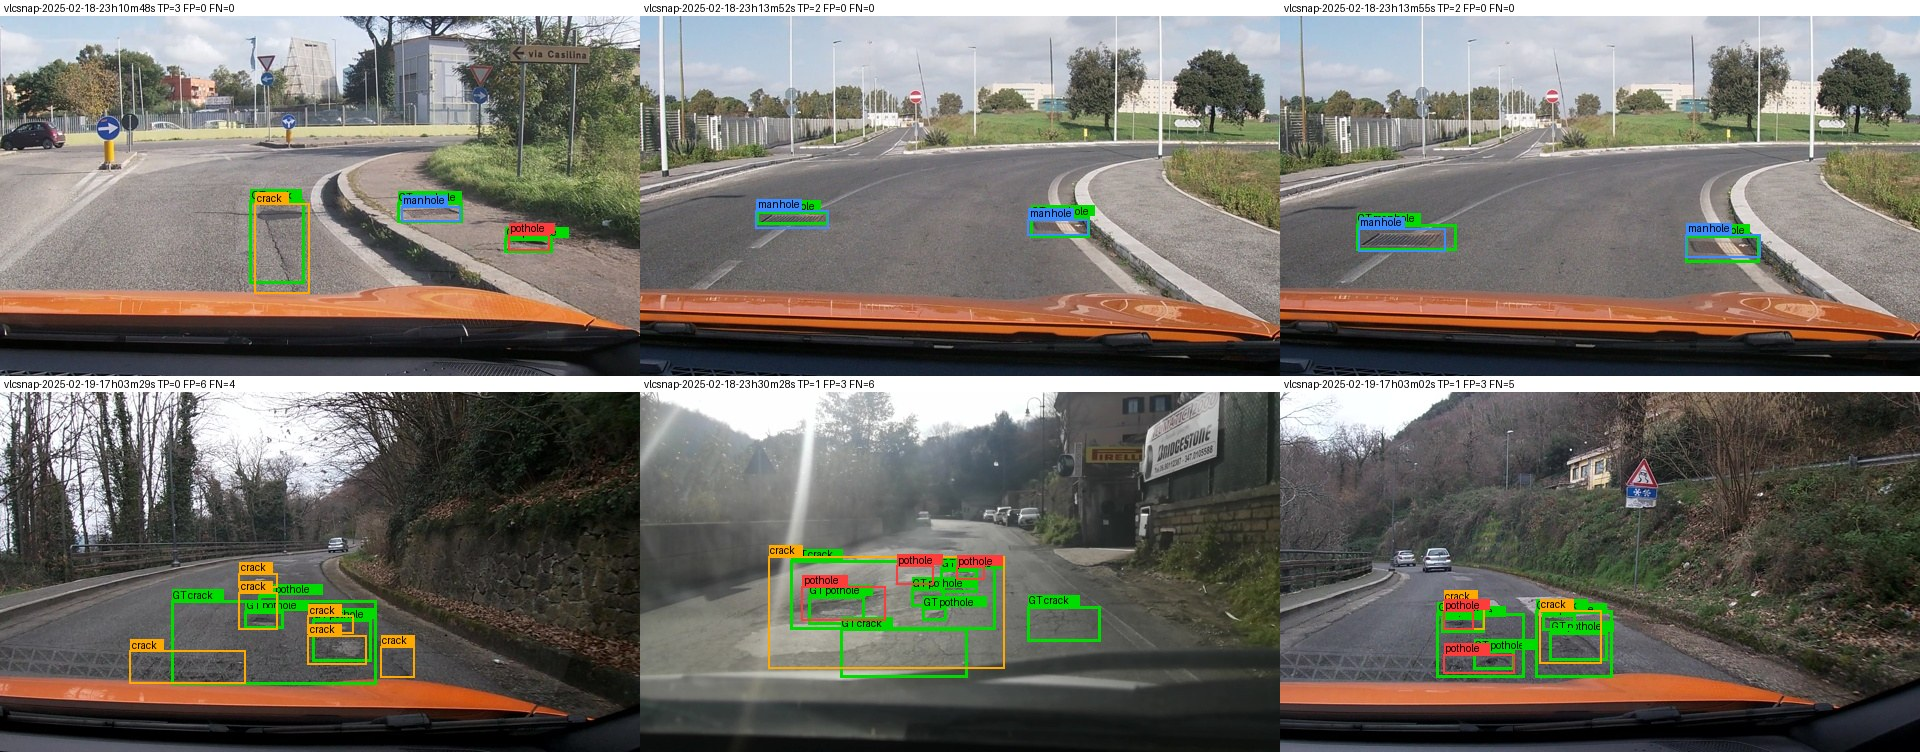

In [20]:
for key in ('e0', BEST):
    for r in viz.make_figures(PREDS / f'{key}.jsonl', FIGS, key):
        print(r['file'], r['kind'], f"TP={r['tp']} FP={r['fp']} FN={r['fn']}", r['gt'], '→', r['pred'])
from IPython.display import Image as IPImage, display
display(IPImage(str(FIGS / f'{BEST}_grid.jpg')))
sync_report()

In [21]:
!python -m lab.report_table
!python scripts/check_submission.py

| Mã | Setup | Tham số huấn luyện | VRAM đỉnh (GB) | Phút | F1 | CI95 | FP/ảnh | F1 pothole | F1 crack | F1 manhole |
|---|---|---|---|---|---|---|---|---|---|---|
| E0 | zero-shot | 0 |  |  | 0.111 | 0.084–0.143 | 0.86 | 0.162 | 0.029 | 0.243 |
| E1 | LoRA LLM | 33.030.144 | 6.55 | 47.3 | 0.263 | 0.227–0.301 | 1.16 | 0.181 | 0.201 | 0.488 |
| E2 | + projector | 142.135.296 | 8.25 | 48.0 | 0.338 | 0.300–0.377 | 1.10 | 0.185 | 0.273 | 0.606 |
| E3 | + LoRA ViT | 148.426.752 | 10.36 | 53.0 | 0.439 | 0.399–0.480 | 0.88 | 0.257 | 0.385 | 0.685 |
| E4 coord_scale=norm1000 | coord_scale_norm1000 | 148.426.752 | 10.36 | 53.0 | 0.439 | 0.399–0.480 | 0.88 | 0.257 | 0.385 | 0.685 |
| E4 coord_scale=pixel | coord_scale_pixel | 148.426.752 | 10.34 | 52.8 | 0.407 | 0.370–0.446 | 0.98 | 0.247 | 0.343 | 0.660 |

| Mã | parse_valid | P | R | mean IoU | TP | FP | FN |
|---|---|---|---|---|---|---|---|
| E0 | 0.958 | 0.158 | 0.086 | 0.619 | 50 | 267 | 533 |
| E1 | 0.997 | 0.284 | 0.245 | 0.679 | 143 | 3

## 9. E5 (tuỳ chọn, +10): GRPO với reward IoU

In [22]:
RUN_E5 = False   # đổi thành True để chạy GRPO (tuỳ chọn, +10)
if RUN_E5:
    !python -m pytest -q lab_tests/test_reward.py

In [23]:
if RUN_E5:
    from datasets import Dataset
    from trl import GRPOConfig, GRPOTrainer
    from lab.reward import grpo_reward, gt_boxes_norm1000
    from PIL import Image

    E5_DIR = RUNS / 'e5'
    grpo_entries = vlm.subsample(train_e, 0.2, seed=5)
    def gen():
        for e in grpo_entries:
            yield {'prompt': [{'role': 'user', 'content': PROMPT}],
                   'image': Image.open(Path('data') / e['image_path']).convert('RGB'),
                   'gt': json.dumps([[lab, list(bb)] for lab, bb in gt_boxes_norm1000(e['objects'])])}
    grpo_ds = Dataset.from_generator(gen)

    if not (E5_DIR / 'run.json').exists():
        model, processor = vlm.load_trained(RUNS / BEST, is_trainable=True)   # khởi tạo từ adapter tốt nhất
        model.enable_input_require_grads()
        cfg = GRPOConfig(output_dir=str(E5_DIR), num_generations=4, max_completion_length=128, max_steps=60,
                         learning_rate=5e-6, beta=0.0, per_device_train_batch_size=4, gradient_accumulation_steps=2,
                         fp16=True, bf16=False, gradient_checkpointing=True, use_vllm=False, logging_steps=1,
                         save_strategy='no', report_to='none', remove_unused_columns=False, log_completions=False)
        trainer = GRPOTrainer(model=model, reward_funcs=grpo_reward, args=cfg, train_dataset=grpo_ds,
                              processing_class=processor)
        torch.cuda.reset_peak_memory_stats(); import time; t0 = time.time()
        trainer.train()
        model.save_pretrained(E5_DIR / 'adapter')
        if (RUNS / BEST / vlm.EXTRA_FILE).exists():       # projector không đổi trong GRPO: dùng lại của BEST
            shutil.copy(RUNS / BEST / vlm.EXTRA_FILE, E5_DIR / vlm.EXTRA_FILE)
        run = {'trainable_params': sum(p.numel() for p in model.parameters() if p.requires_grad),
               'peak_vram_gb': round(torch.cuda.max_memory_allocated() / 2**30, 2),
               'train_minutes': round((time.time() - t0) / 60, 1), 'init': BEST}
        (E5_DIR / 'run.json').write_text(json.dumps(run, indent=2))
        Path('report/e5_grpo_log.json').write_text(json.dumps(trainer.state.log_history, indent=1))
        del trainer, model; vlm.cleanup()

In [24]:
if RUN_E5:
    run = json.loads((E5_DIR / 'run.json').read_text())
    if not Path('report/extra/e5.json').exists():
        model, processor = vlm.load_trained(E5_DIR)
        vlm.predict(model, processor, test_e, 'data', PROMPT, PREDS / 'e5.jsonl')
        del model; vlm.cleanup()
    r5 = score(PREDS / 'e5.jsonl', 'E5', 'report/extra/e5.json',
               meta={k: run[k] for k in ('trainable_params', 'peak_vram_gb', 'train_minutes')})

    # Dấu hiệu reward hacking: tỉ lệ trả [] và box khổng lồ (>50% khung hình), so với SFT tốt nhất
    def hack_stats(path):
        rows = [parse_output(r['raw']) for r in read_jsonl(path)]
        ok = [p for p in rows if p is not None]
        boxes = [b for p in ok for b in p]
        giant = sum((b['bbox'][2]-b['bbox'][0]) * (b['bbox'][3]-b['bbox'][1]) > 0.5e6 for b in boxes)
        return {'empty_rate': round(sum(not p for p in ok) / len(rows), 3), 'boxes/img': round(len(boxes) / len(rows), 2),
                'giant_boxes': giant}
    print('SFT', BEST, hack_stats(PREDS / f'{BEST}.jsonl'))
    print('E5     ', hack_stats(PREDS / 'e5.jsonl'))
    log = json.loads(Path('report/e5_grpo_log.json').read_text())
    print([round(x['reward'], 3) for x in log if 'reward' in x])
    sync_report()

In [25]:
# Lấy report/ về máy rồi chép vào repo local.
# Kaggle: tab Output của phiên bản notebook → tải day10_v2/report (hoặc report.zip).  Colab: tự tải.
OUT_ZIP = '/kaggle/working/report.zip' if ON_KAGGLE else '/content/report.zip'
!zip -qr {OUT_ZIP} report
if not ON_KAGGLE:
    from google.colab import files
    files.download(OUT_ZIP)